<a href="https://colab.research.google.com/github/naik-aarya/Handwritten_Digit_classificaion/blob/main/Handwritten_Digit_classificaion_using__CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Handwritten Digit classificaion**

https://www.kaggle.com/datasets/olafkrastovski/handwritten-digits-0-9

**Downloaded data**

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("olafkrastovski/handwritten-digits-0-9")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'handwritten-digits-0-9' dataset.
Path to dataset files: /kaggle/input/handwritten-digits-0-9


**Listed all folders**

In [ ]:
import os
print(os.listdir(path))

['7', '2', '5', '8', '0', '3', '1', '4', '9', '6']


**Visualise few images**

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image #PIL : python image library used to display images
path

'/kaggle/input/handwritten-digits-0-9'

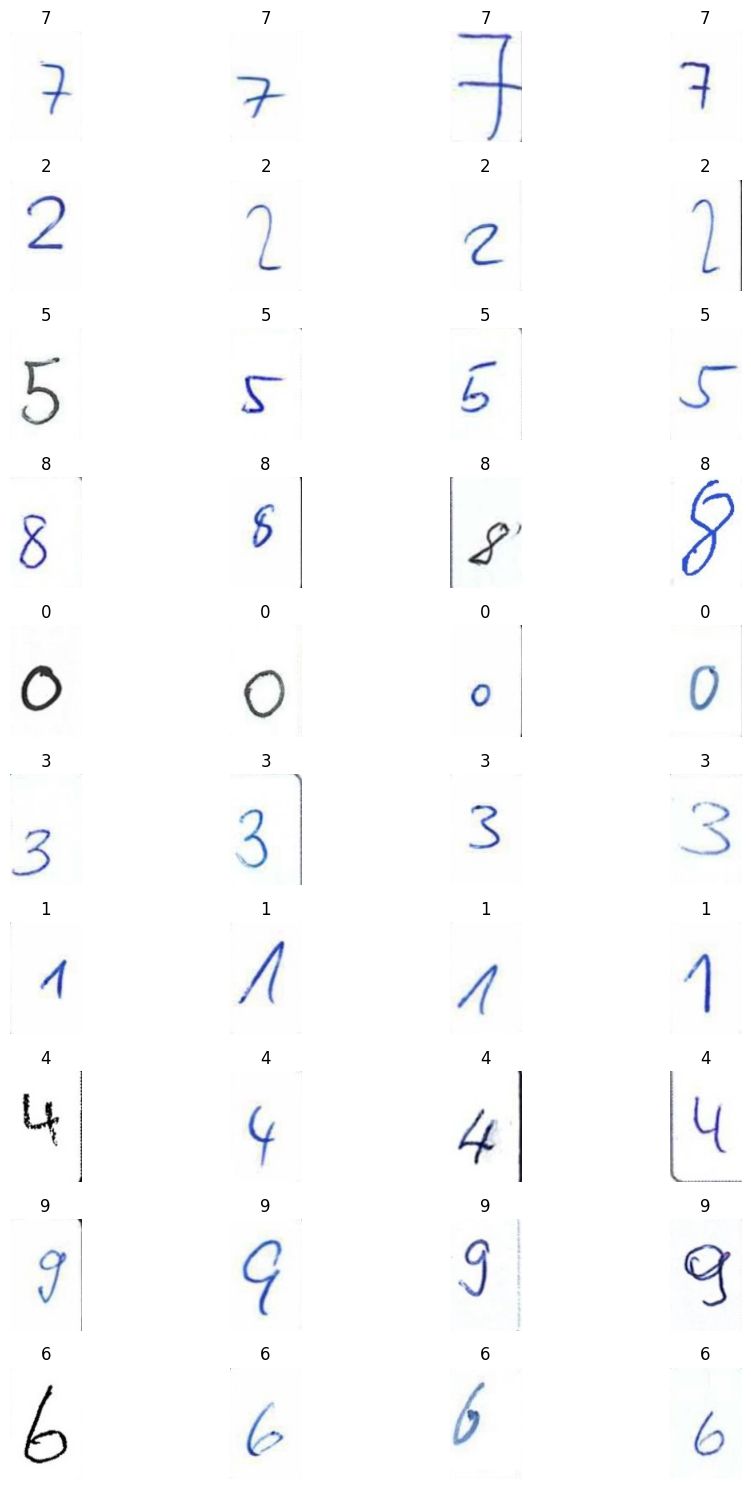

In [ ]:
plt.figure(figsize=(10,15))
i = 1
for class_name in os.listdir(path): #looping through all folders
  class_path = os.path.join(path,class_name) #creating path for each folder
 # print(class_path)
  if os.path.isdir(class_path): # if path exists
    images= os.listdir(class_path)[:4] # 4 images in each folders

    for img in images:
      img_path = os.path.join(class_path,img)
      #print(img_path)
      img= Image.open(img_path)

      plt.subplot(10,4,i)
      plt.imshow(img)
      plt.title(class_name)
      plt.axis('off')

      i+=1
plt.tight_layout()
plt.show()


**Number of Images in each folder**

In [ ]:
for class_name in os.listdir(path): #looping through all folders
  class_path = os.path.join(path,class_name)
  if os.path.isdir(class_path):
    count = len(os.listdir(class_path))
    print(class_name,'-->',count)

7 --> 2116
2 --> 2233
5 --> 2126
8 --> 2085
0 --> 2236
3 --> 2202
1 --> 2241
4 --> 2179
9 --> 2016
6 --> 2121


**Create Dataframe**

In [ ]:
data=[]
for class_name in os.listdir(path): #looping through all folders
  class_path = os.path.join(path,class_name)
  if os.path.isdir(class_path):
    for img in os.listdir(class_path):
      img_path = os.path.join(class_path,img)
      data.append([img_path,class_name])




In [ ]:
import pandas as pd
df = pd.DataFrame(data,columns=["img_path","label"])
df

,img_path,label
0,/kaggle/input/handwritten-digits-0-9/7/Seven_f...,7
1,/kaggle/input/handwritten-digits-0-9/7/Seven_f...,7
2,/kaggle/input/handwritten-digits-0-9/7/Seven_f...,7
3,/kaggle/input/handwritten-digits-0-9/7/Seven_f...,7
4,/kaggle/input/handwritten-digits-0-9/7/Seven_f...,7
...,...,...
21550,/kaggle/input/handwritten-digits-0-9/6/Six_ful...,6
21551,/kaggle/input/handwritten-digits-0-9/6/Six_ful...,6
21552,/kaggle/input/handwritten-digits-0-9/6/Six_ful...,6
21553,/kaggle/input/handwritten-digits-0-9/6/Six_ful...,6


In [ ]:
# shuffle data
df = df.sample(frac=1,random_state=42).reset_index(drop=True)
df

,img_path,label
0,/kaggle/input/handwritten-digits-0-9/0/Zero_fu...,0
1,/kaggle/input/handwritten-digits-0-9/3/Three_f...,3
2,/kaggle/input/handwritten-digits-0-9/2/Two_ful...,2
3,/kaggle/input/handwritten-digits-0-9/3/Three_f...,3
4,/kaggle/input/handwritten-digits-0-9/9/Nine_fu...,9
...,...,...
21550,/kaggle/input/handwritten-digits-0-9/3/Three_f...,3
21551,/kaggle/input/handwritten-digits-0-9/3/Three_f...,3
21552,/kaggle/input/handwritten-digits-0-9/5/Five_fu...,5
21553,/kaggle/input/handwritten-digits-0-9/7/Seven_f...,7


**Split data for training , testing , validation**

In [ ]:
train_size= int(0.7*len(df))
test_size = int(0.15*len(df))
val_size= int(0.15*len(df))
print(f"train_size-->{train_size},test_size-->{test_size},val_size-->{val_size}")

train_size-->15088,test_size-->3233,val_size-->3233


In [ ]:
train_data = df.iloc[: train_size]
val_data = df.iloc[train_size:train_size+val_size ]
test_data = df.iloc[train_size+val_size:]
print(train_data.shape)
print(val_data.shape)
print(test_data.shape)

(15088, 2)
(3233, 2)
(3234, 2)


**height and width of an image**

In [ ]:
img_path = df['img_path'][0]
image = Image.open(img_path)
width,height = image.size
print('height',height)
print('width',width)

height 140
width 90


**Image data cleaning**

In [ ]:
import tensorflow
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
batch_size=32
img_height= 128
img_width=128

In [ ]:
# Normalization
data_generator = ImageDataGenerator(
    rescale=1.0/255, # Normalization: Pixel values go from 0–255 → 0–1
    rotation_range=40, #Randomly rotates image up to ±40 degrees
    width_shift_range=0.2, #Moves image left/right by 20%
    height_shift_range=0.2, # Moves image up/down by 20%
    shear_range=0.2, # Slants the image (like pushing it sideways)
    zoom_range=0.2, # Zoom in/out randomly
    horizontal_flip=True, #Flips image left ↔ right
    fill_mode='nearest' #This fills those gaps using nearest pixels
)

In [ ]:
train_generator = data_generator.flow_from_dataframe(
  dataframe=train_data,
  x_col="img_path",
  y_col="label",
  target_size=(img_height, img_width),
  batch_size=batch_size,
  class_mode="categorical",
  shuffle=True,
  seed=42
)

Found 15088 validated image filenames belonging to 10 classes.


In [ ]:
test_generator = data_generator.flow_from_dataframe(
  dataframe=test_data,
  x_col="img_path",
  y_col="label",
  target_size=(img_height, img_width),
  batch_size=batch_size,
  class_mode="categorical",
  shuffle=True,
  seed=42
)

Found 3234 validated image filenames belonging to 10 classes.


In [ ]:
val_generator = data_generator.flow_from_dataframe(
  dataframe=val_data,
  x_col="img_path",
  y_col="label",
  target_size=(img_height, img_width),
  batch_size=batch_size,
  class_mode="categorical",
  shuffle=True,
  seed=42
)

Found 3233 validated image filenames belonging to 10 classes.


In [ ]:
for image_batch, labels_batch in train_generator:
    print(f"Train Shape: {image_batch.shape} (Batches = {len(train_generator)})")
    print(f"Train Label Shape: {labels_batch.shape}\n")
    break

for image_batch, labels_batch in val_generator:
    print(f"Validation Shape: {image_batch.shape} (Batches = {len(val_generator)})")
    print(f"Validation Label Shape: {labels_batch.shape}\n")
    break

for image_batch, labels_batch in test_generator:
    print(f"Test Shape: {image_batch.shape} (Batches = {len(test_generator)})")
    print(f"Test Label Shape: {labels_batch.shape}\n")
    break

Train Shape: (32, 128, 128, 3) (Batches = 472)
Train Label Shape: (32, 10)

Validation Shape: (32, 128, 128, 3) (Batches = 102)
Validation Label Shape: (32, 10)

Test Shape: (32, 128, 128, 3) (Batches = 102)
Test Label Shape: (32, 10)



**Model Building**

In [ ]:
from tensorflow.keras import layers,models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import categorical_crossentropy

In [ ]:
n_classes=10
cnn_model = models.Sequential([
    layers.Input(shape=(128,128,3)),
    layers.Conv2D(32 , kernel_size=(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64 , kernel_size=(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64 , kernel_size=(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64,activation='relu'),
    layers.Dense(n_classes,activation='softmax')

])

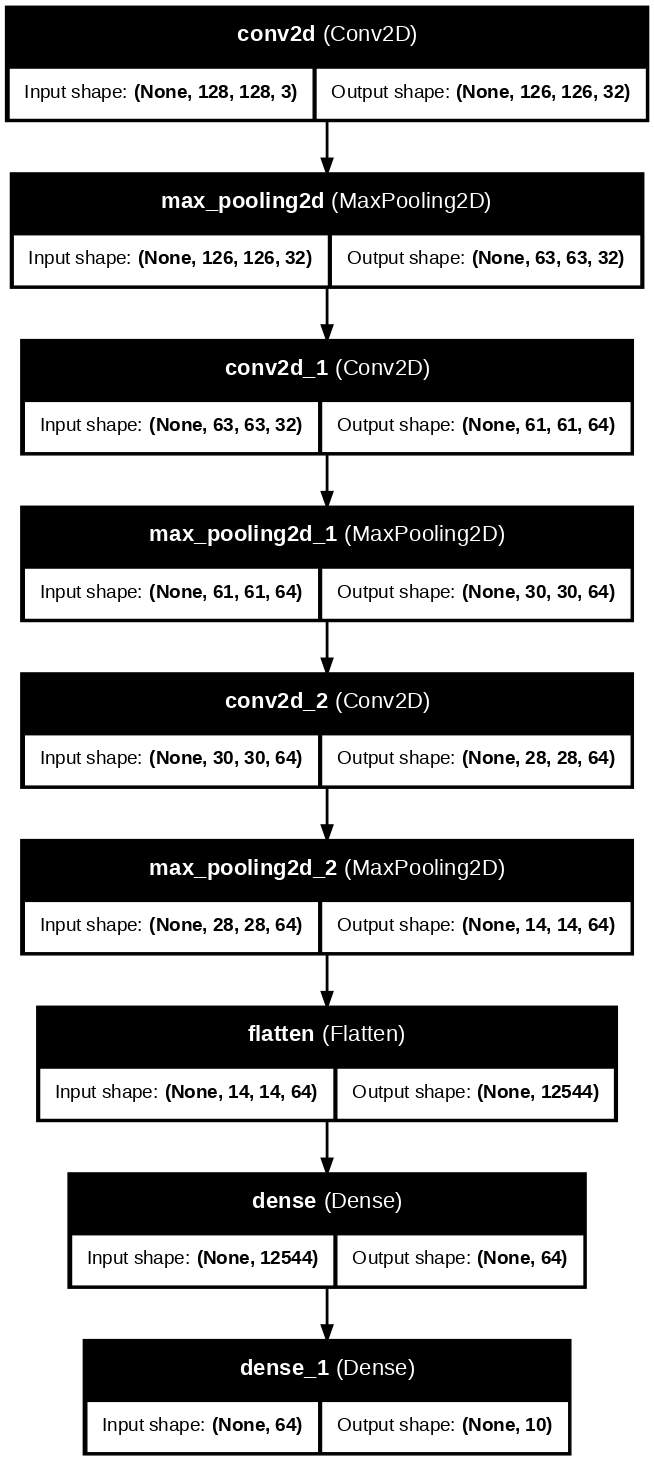

In [ ]:
from tensorflow.keras.utils import plot_model
plot_model(cnn_model, to_file='model_plot.png', show_shapes=True, show_layer_names=True, dpi=100, expand_nested=True)

In [ ]:
cnn_model.compile(loss=categorical_crossentropy,optimizer=Adam(),metrics=['accuracy'])

In [ ]:
cnn = cnn_model.fit(train_generator,epochs=10,validation_data=val_generator,verbose=1)

Epoch 1/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 308s 649ms/step - accuracy: 0.1385 - loss: 2.2771 - val_accuracy: 0.2181 - val_loss: 2.1699
Epoch 2/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 289s 612ms/step - accuracy: 0.3537 - loss: 1.8496 - val_accuracy: 0.4256 - val_loss: 1.6890
Epoch 3/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 293s 622ms/step - accuracy: 0.4985 - loss: 1.4634 - val_accuracy: 0.5512 - val_loss: 1.3014
Epoch 4/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 292s 618ms/step - accuracy: 0.5688 - loss: 1.2492 - val_accuracy: 0.5719 - val_loss: 1.2267
Epoch 5/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 294s 623ms/step - accuracy: 0.6378 - loss: 1.0743 - val_accuracy: 0.6842 - val_loss: 0.9740
Epoch 6/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 290s 614ms/step - accuracy: 0.6860 - loss: 0.9463 - val_accuracy: 0.7006 - val_loss: 0.8890
Epoch 7/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 296s 628ms/step - accuracy: 0.7140 - loss: 0.8548 - val_accuracy: 0.7092 - val_loss: 0.8599
Epoch 8/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 303s 642ms/step - accuracy: 0.7391 -

In [ ]:
train_loss, train_accuracy = cnn_model.evaluate(train_generator, verbose=1)
print(f'Training accuracy: {train_accuracy:.4f}')

# Evaluate on the test data
test_loss, test_accuracy = cnn_model.evaluate(test_generator, verbose=1)
print(f'Test accuracy: {test_accuracy:.4f}')

In [ ]:
# Retrieve metrics from the training history
acc = cnn.history['accuracy']
val_acc = cnn.history['val_accuracy']
loss = cnn.history['loss']
val_loss = cnn.history['val_loss']

epochs_range = range(1, len(acc) + 1)

# Plot accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy for CNN')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss for CNN')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

img_path = "three.jpg"

# Load image
img = image.load_img(img_path, target_size=(128, 128))  # same as training

# Convert to array
img_array = image.img_to_array(img)

# Normalize
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

In [ ]:
prediction = cnn_model.predict(img_array)
prediction

In [ ]:
predicted_class = np.argmax(prediction)

print("Predicted Class:", predicted_class)